# Modelo KNN — Regresión del volumen de ventas

**Objetivo:** predecir `log_bought` (= `log1p` de las compras del último mes) con un modelo de
**K-Vecinos más cercanos para regresión**

**Flujo:**
1. Cargar los 4 datasets limpios.
2. Definir features (X) y objetivo (Y) — **sin fuga de información**.
3. Implementar KNN regresión (media de los `k` vecinos) y MAPE.
4. Experimentar con distintos `k` (con particiones repetidas + estandarización).
5. Comparar las 4 variantes de dataset y elegir el mejor modelo.

## 1. Librerías y rutas

Se trabaja con rutas **relativas**, localizando la carpeta `Limpieza de datos/` sin importar
desde dónde se ejecute el notebook.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist

CSV_DIRNAME = "Limpieza de datos"

def _find_data_dir(start):
    here = Path(start).resolve()
    for base in [here, *here.parents]:
        cand = base / CSV_DIRNAME
        if cand.is_dir():
            return cand
    raise FileNotFoundError(f"No se encontro la carpeta '{CSV_DIRNAME}'.")

try:
    _start = Path(__file__).resolve().parent
except NameError:
    _start = Path.cwd()

DATA_DIR = _find_data_dir(_start)
MODEL_DIR = Path.cwd()

print(f"Carpeta de datos:   {DATA_DIR}")
print(f"Carpeta del modelo: {MODEL_DIR}")

Carpeta de datos:   /home/barrera/Documentos/Udea/2026-2/Modelos y simulación/Trabajo de amazon/Amazon product sales/Limpieza de datos
Carpeta del modelo: /home/barrera/Documentos/Udea/2026-2/Modelos y simulación/Trabajo de amazon/Amazon product sales/Modelos entrenados


## 2. Carga de los 4 datasets

Cada variante resuelve distinto las dos decisiones abiertas (precio y delivery). Ver `README.md`
para el detalle.

In [2]:
datasets = {}
for v in [1, 2, 3, 4]:
    ruta = DATA_DIR / f"dataset_v{v}.csv"
    datasets[v] = pd.read_csv(ruta)
    d = datasets[v]
    print(f"v{v}: {d.shape[0]:>6} filas x {d.shape[1]:>2} columnas  "
          f"| delivery_cost={'delivery_cost' in d.columns}  | nulos={d.isna().sum().sum()}")

v1:  24436 filas x 20 columnas  | delivery_cost=True  | nulos=0
v2:  24436 filas x 18 columnas  | delivery_cost=False  | nulos=0
v3:  31202 filas x 20 columnas  | delivery_cost=True  | nulos=0
v4:  31202 filas x 18 columnas  | delivery_cost=False  | nulos=0


## 3. Definición de features (X) y objetivo (Y)

**Objetivo del modelo:** `log_bought` (continua, la que usa la regresión KNN).

**Regla anti-fuga:** se excluyen del conjunto de features:
- `log_bought` (es el target),
- `bought_in_last_month` (origen del target),
- `bought_cat` (derivada del target).

Para evitar multicolinealidad se conserva la versión `log_*` de cada variable numérica y se
descarta el crudo equivalente (`current_price`, `Number_of_reviews`, `title_word_count`,
`delivery_cost`). `buy_box_status` se convierte a dummy (`unknown`=1).

In [3]:
TARGET = "log_bought"
LEAK_COLS = ["log_bought", "bought_in_last_month", "bought_cat"]

LOG_PAIRS = {
    "current_price": "log_price",
    "Number_of_reviews": "log_reviews",
    "title_word_count": "log_title_words",
    "delivery_cost": "log_delivery_cost",
}

def construir_xy(d):
    d = d.copy()
    d["buy_box_unknown"] = (d["buy_box_status"] == "unknown").astype(int)
    d = d.drop(columns=["buy_box_status"])

    drop_cols = list(LEAK_COLS)
    for raw, log in LOG_PAIRS.items():
        if raw in d.columns and log in d.columns:
            drop_cols.append(raw)

    feature_cols = [c for c in d.columns if c not in drop_cols]
    X = d[feature_cols].to_numpy(dtype=float)
    Y = d[TARGET].to_numpy(dtype=float)
    return X, Y, feature_cols

X, Y, feature_cols = construir_xy(datasets[3])
print(f"Features ({len(feature_cols)}):")
for c in feature_cols:
    print("  -", c)
print(f"\nX shape: {X.shape} | Y shape: {Y.shape}")

Features (13):
  - Rating
  - has_discount
  - is_best_seller_flag
  - is_sponsored_flag
  - has_coupon
  - is_free_delivery
  - has_sustainability_badge
  - is_price_outlier
  - log_price
  - log_reviews
  - log_title_words
  - log_delivery_cost
  - buy_box_unknown

X shape: (31202, 13) | Y shape: (31202,)


## 4. KNN para regresión y métrica MAPE

**KNN regresión:** para cada muestra de test se calculan las distancias a todas las de
entrenamiento, se toman los `k` vecinos más cercanos y se predice la **media** de sus valores.

**MAPE:** error porcentual absoluto medio. Como el objetivo está en escala log, el MAPE se
interpreta en esa escala.

In [4]:
def knn_regresion(k, X_train, Y_train, X_test):
    """KNN para regresion: predice la media de los k vecinos mas cercanos.
    Implementacion vectorizada con NumPy (sin bucles por fila).
    """
    distancias = cdist(X_test, X_train)                    # (n_test, n_train)
    idx = np.argpartition(distancias, k, axis=1)[:, :k]    # k vecinos mas cercanos
    Y_est = Y_train[idx].mean(axis=1)                      # media vectorizada
    return Y_est, distancias


def MAPE(Y_est, Y):
    """Mean Absolute Percentage Error."""
    N = np.size(Y)
    epsilon = 1e-10
    return np.sum(np.abs((Y_est.reshape(N, 1) - Y.reshape(N, 1)) /
                         (Y.reshape(N, 1) + epsilon))) / N


## 5. Función `experimentar`

Para cada `k` se repiten `n_particiones` particiones train/test (estratificadas por `bought_cat`).
En cada una: separar train/test, **estandarizar** con `StandardScaler` (ajustado solo en train),
entrenar KNN y calcular el MAPE de test.

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


def experimentar(ks, X, Y, y_strat, n_particiones=5, random_state=0):
    """Ejecuta KNN para cada k repitiendo particiones train/test."""
    resultados = pd.DataFrame()
    idx = 0
    for k in ks:
        for j in range(n_particiones):
            Xtr, Xte, Ytr, Yte = train_test_split(
                X, Y, test_size=0.2, random_state=random_state + j, stratify=y_strat
            )
            scaler = StandardScaler().fit(Xtr)
            Xtr_s = scaler.transform(Xtr)
            Xte_s = scaler.transform(Xte)

            Yest, _ = knn_regresion(k, Xtr_s, Ytr, Xte_s)
            error = MAPE(Yest, Yte)

            resultados.loc[idx, "k-vecinos"] = k
            resultados.loc[idx, "error de prueba"] = error
            resultados.loc[idx, "particion"] = j
            idx += 1
    return resultados

## 6. Experimentos sobre la variante v3

Se prueban varios valores de `k` y se resume el MAPE medio (± desviación) por cada uno.

In [6]:
y_strat = datasets[3]["bought_cat"].to_numpy()

ks = [3, 5, 7, 9, 11, 15, 21, 31, 41]
res_v3 = experimentar(ks, X, Y, y_strat, n_particiones=5, random_state=0)
res_v3.head()

,k-vecinos,error de prueba,particion
0,3.0,0.032803,0.0
1,3.0,0.034740,1.0
2,3.0,0.033312,2.0
3,3.0,0.033588,3.0
4,3.0,0.033967,4.0


In [7]:
resumen_v3 = (res_v3.groupby("k-vecinos")["error de prueba"]
              .agg(["mean", "std"])
              .rename(columns={"mean": "MAPE medio", "std": "MAPE std"}))
resumen_v3

,MAPE medio,MAPE std
k-vecinos,,
3.0,0.033682,0.000728
5.0,0.033251,0.000787
7.0,0.033303,0.000776
9.0,0.033477,0.000675
11.0,0.033667,0.000778
15.0,0.034283,0.000760
21.0,0.035332,0.000620
31.0,0.037305,0.000635
41.0,0.039934,0.000677


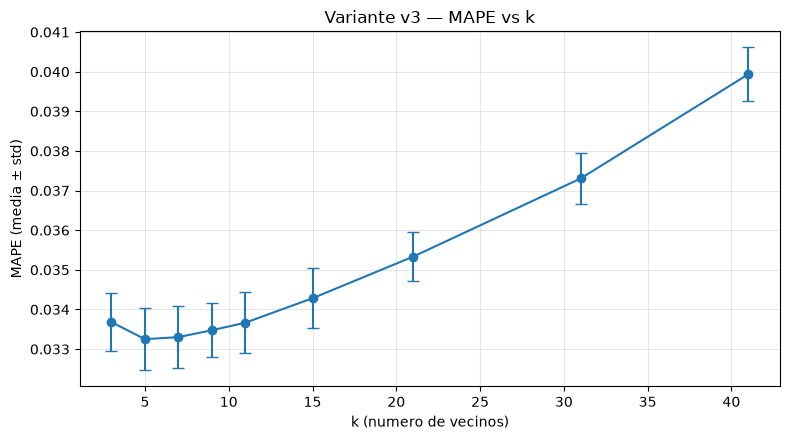

Mejor k para v3: 5.0 (MAPE medio = 0.0333)


In [8]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.errorbar(resumen_v3.index, resumen_v3["MAPE medio"], yerr=resumen_v3["MAPE std"],
            marker="o", capsize=4)
ax.set_xlabel("k (numero de vecinos)")
ax.set_ylabel("MAPE (media ± std)")
ax.set_title("Variante v3 — MAPE vs k")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

mejor_k_v3 = resumen_v3["MAPE medio"].idxmin()
print(f"Mejor k para v3: {mejor_k_v3} "
      f"(MAPE medio = {resumen_v3.loc[mejor_k_v3, 'MAPE medio']:.4f})")

## 7. Comparación entre las 4 variantes de dataset

Se repite el experimento (alrededor del mejor `k`) para cada variante y se compara el MAPE.

In [9]:
ks_cmp = [3, 5, 7, 9, 11, 15, 21]

comparacion = {}
for v in [1, 2, 3, 4]:
    Xv, Yv, _ = construir_xy(datasets[v])
    strat = datasets[v]["bought_cat"].to_numpy()
    res = experimentar(ks_cmp, Xv, Yv, strat, n_particiones=5, random_state=0)
    comparacion[v] = res.groupby("k-vecinos")["error de prueba"].agg(["mean", "std"])

tabla = pd.DataFrame({f"v{v}": comparacion[v]["mean"] for v in comparacion})
tabla

,v1,v2,v3,v4
k-vecinos,,,,
3.0,0.029633,0.029667,0.033682,0.033695
5.0,0.029636,0.029614,0.033251,0.033221
7.0,0.029807,0.029805,0.033303,0.033222
9.0,0.030064,0.030030,0.033477,0.033415
11.0,0.030274,0.030232,0.033667,0.033577
15.0,0.030874,0.030759,0.034283,0.034140
21.0,0.032104,0.031867,0.035332,0.035092


In [10]:
mejor = None
for v in comparacion:
    k_best = comparacion[v]["mean"].idxmin()
    err = comparacion[v]["mean"].min()
    print(f"v{v}: mejor k = {k_best:>2}  ->  MAPE medio = {err:.4f}")
    if mejor is None or err < mejor[2]:
        mejor = (v, k_best, err)

print(f"\n=> Mejor combinacion: variante v{mejor[0]}, k={mejor[1]}, MAPE medio={mejor[2]:.4f}")

v1: mejor k = 3.0  ->  MAPE medio = 0.0296
v2: mejor k = 5.0  ->  MAPE medio = 0.0296
v3: mejor k = 5.0  ->  MAPE medio = 0.0333
v4: mejor k = 5.0  ->  MAPE medio = 0.0332

=> Mejor combinacion: variante v2, k=5.0, MAPE medio=0.0296


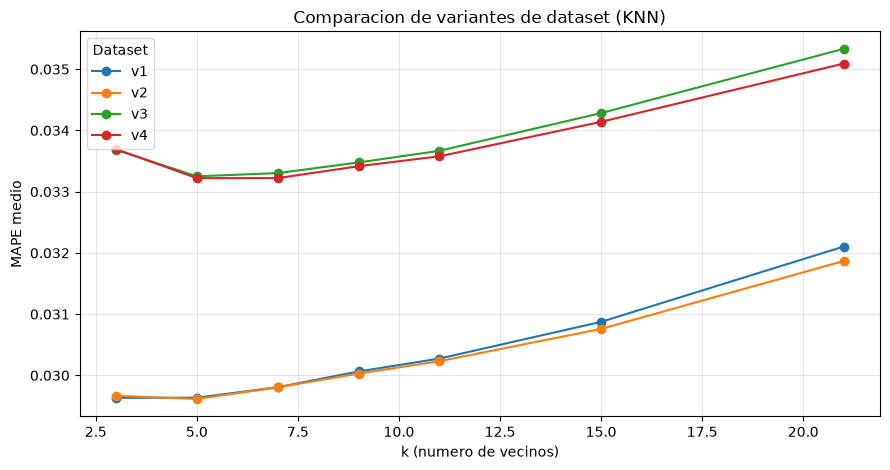

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.8))
for v in comparacion:
    ax.plot(comparacion[v].index, comparacion[v]["mean"], marker="o", label=f"v{v}")
ax.set_xlabel("k (numero de vecinos)")
ax.set_ylabel("MAPE medio")
ax.set_title("Comparacion de variantes de dataset (KNN)")
ax.legend(title="Dataset")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()